# Simulating a network surrogate of the Ackley function

This notebook mirrors `test/ML/sim_NN.cpp`. A surrogate of the Ackley function of two variables on $[0,1]^2$,
saved as a dictionary by `torch.save`, is read by MC++ without PyTorch: a piecewise-linear Kolmogorov-Arnold
network (`ackley2d_KAN-*.pt`) for a `KAN`, or a dense ReLU network (`ackley2d_ANN-*.pt`) for an `MLP`. The
network is inserted in a DAG as an `FFKAN` or `FFMLP` operation, evaluated at random points, and compared with
the Ackley function.

**Requirements.** pymcpp 5.2 or later, NumPy and Matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, LogLocator, NullFormatter
import pymcpp

file = "../test/ML/ackley2d_KAN-TITO-h5x5x5-g8x8x8x8.pt"   # or ackley2d_ANN-TW-h16x16.pt, ...
N = 1000

## The network in a DAG

The file is read once: `NETIO.read_dict` returns its dictionary, which tells the type of network and is
given to a `KAN` or an `MLP` by `set_data`. The scalings of the file are folded into the network, which maps
the raw inputs to the raw outputs.

In [2]:
D = pymcpp.NETIO.read_dict(file)
isKAN = (D.type == "KANmodel")
NN, Op = (pymcpp.KAN(), pymcpp.FFKAN()) if isKAN else (pymcpp.MLP(), pymcpp.FFMLP())
NN.set_data(D)
print(D.type, "with widths", D.widths, ("and %d segments" % NN.nwei) if isKAN else "")

DAG = pymcpp.FFGraph()
X = DAG.add_vars(2)
Z = Op(X, NN)

KANmodel with widths [2, 5, 5, 5, 1] and 520 segments


## Simulation against the Ackley function

$$f(x_1,x_2) = -20\,\exp\!\Big(-0.2\sqrt{\tfrac12(x_1^2+x_2^2)}\Big) - \exp\!\Big(\tfrac12(\cos 2\pi x_1+\cos 2\pi x_2)\Big) + e + 20$$

In [3]:
def ackley(x):
    return (-20. * np.exp(-0.2 * np.sqrt(0.5 * (x[:, 0]**2 + x[:, 1]**2)))
            - np.exp(0.5 * (np.cos(2. * np.pi * x[:, 0]) + np.cos(2. * np.pi * x[:, 1]))) + np.e + 20.)

rng = np.random.default_rng(0)
xs = rng.random((N, 2))                                             # N random points of [0,1]^2
z_net = np.array([DAG.eval(Z, X, list(x))[0] for x in xs])          # network, through the DAG
z_ack = ackley(xs)                                                  # Ackley function

err = z_net - z_ack
print("error of the network: RMS %.4g, largest %.4g" % (np.sqrt(np.mean(err**2)), np.abs(err).max()))

fout = file[:file.rfind(".")] + ".out"                              # x1, x2, network, Ackley
np.savetxt(fout, np.column_stack([xs, z_net, z_ack]), fmt="%.10g")

error of the network: RMS 0.008721, largest 0.04296


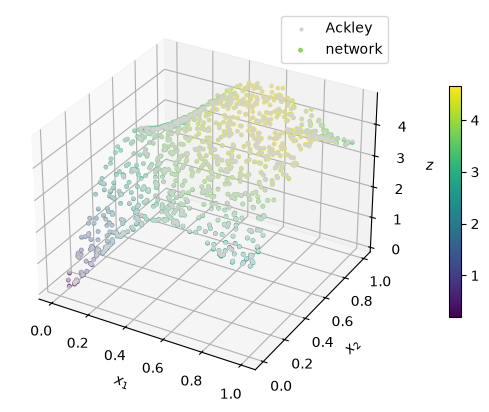

In [4]:
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
ax.scatter(xs[:, 0], xs[:, 1], z_ack, s=4, color="lightgray", label="Ackley")
sc = ax.scatter(xs[:, 0], xs[:, 1], z_net, s=6, c=z_net, cmap="viridis", label="network")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$z$")
ax.legend()
fig.colorbar(sc, shrink=0.6, pad=0.1)
plt.show()

## Parity plot

Predicted against exact values, on logarithmic axes: the relative error of the network is largest near the
minimum of the Ackley function, at the origin, where the values are small. Points where the network is not
positive cannot be shown on these axes, and are counted.

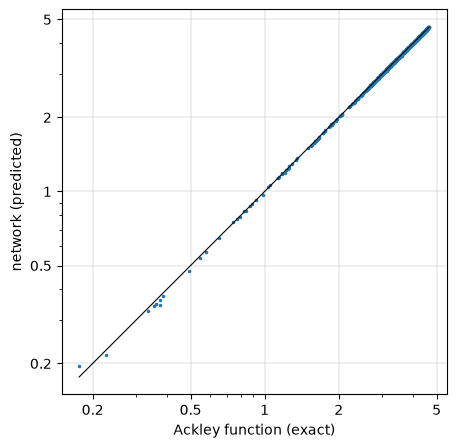

0 of 1000 points with a network value that is not positive


In [5]:
pos = z_net > 0.
lo, hi = min(z_ack.min(), z_net[pos].min()), max(z_ack.max(), z_net.max())

fig, ax = plt.subplots(figsize=(5, 5))
ax.loglog(z_ack[pos], z_net[pos], ".", ms=3)
ax.loglog([lo, hi], [lo, hi], "k-", lw=0.8)
ax.set_xlabel("Ackley function (exact)"); ax.set_ylabel("network (predicted)")
for axis in (ax.xaxis, ax.yaxis):                                   # ticks at 1, 2, 5 per decade
    axis.set_major_locator(LogLocator(subs=(1., 2., 5.)))
    axis.set_major_formatter(FormatStrFormatter("%g"))
    axis.set_minor_formatter(NullFormatter())
ax.set_aspect("equal")
ax.grid(True, which="major", lw=0.3)
plt.show()
print("%d of %d points with a network value that is not positive" % (N - pos.sum(), N))